In [1]:
import sys
sys.path.append("..")

from collections import Counter

import emoji
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
import seaborn as sns

from src.data import add_key, clean_train, load_split
from src.preprocess import URL_PATTERN

sns.set_theme(style="darkgrid")

train, val, test = load_split()
df = pd.concat([train, val], ignore_index=True)   # full labelled file (12,548 tweets)

LABELS = ["Non-sarcastic", "Sarcastic"]
COLORS = {"Non-sarcastic": "steelblue", "Sarcastic": "tomato"}
for frame in (df, test):
    frame["label"] = frame["sarcasm"].map(dict(enumerate(LABELS)))

def bar_labels(ax, fmt="%d", **kw):
    for c in ax.containers:
        ax.bar_label(c, fmt=fmt, padding=2, **kw)
    ax.margins(x=0.1, y=0.12)

In [2]:
# Overview
display(df.head())
pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isnull().sum(), "unique": df.nunique()})

,tweet,sarcasm,sentiment,dialect,sentiment_id,id,label
0,"""#لافروف: #موسكو تأمل بإجراء حوار بناء بشأن ال...",0,NEU,msa,1,2474,Non-sarcastic
1,"""RT @jalalyw: @EHSANFAKEEH تفصيل الخبر لمن يري...",0,NEU,msa,1,12107,Non-sarcastic
2,تحدثنا عن هذا الكتاب الجميل عن خروج المصريين ع...,0,NEU,msa,1,2135,Non-sarcastic
3,"""RT @Jokes__99: بوكيمون ولحقتوه عيل المسيح الد...",1,NEG,msa,0,640,Sarcastic
4,"""أوباما يلاحق محمد بن سلمان !!: https://t.co/x...",0,NEU,msa,1,6766,Non-sarcastic


,dtype,missing,unique
tweet,str,0,12487
sarcasm,int64,0,2
sentiment,str,0,3
dialect,str,0,5
sentiment_id,int64,0,3
id,int64,0,12548
label,str,0,2


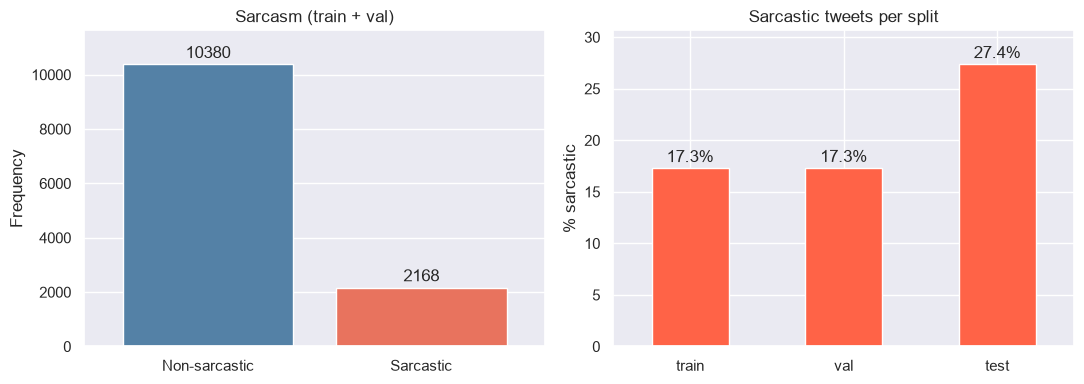

In [3]:
# Sarcasm distribution: counts, and % per split
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ax = sns.countplot(data=df, x="label", order=LABELS, hue="label", palette=COLORS, legend=False, ax=axes[0])
bar_labels(ax)
ax.set(xlabel="", ylabel="Frequency", title="Sarcasm (train + val)")

rate = pd.Series({n: 100 * f["sarcasm"].mean() for n, f in [("train", train), ("val", val), ("test", test)]})
ax = rate.plot.bar(ax=axes[1], rot=0, color="tomato")
bar_labels(ax, "%.1f%%")
ax.set(xlabel="", ylabel="% sarcastic", title="Sarcastic tweets per split")

plt.tight_layout()
plt.show()

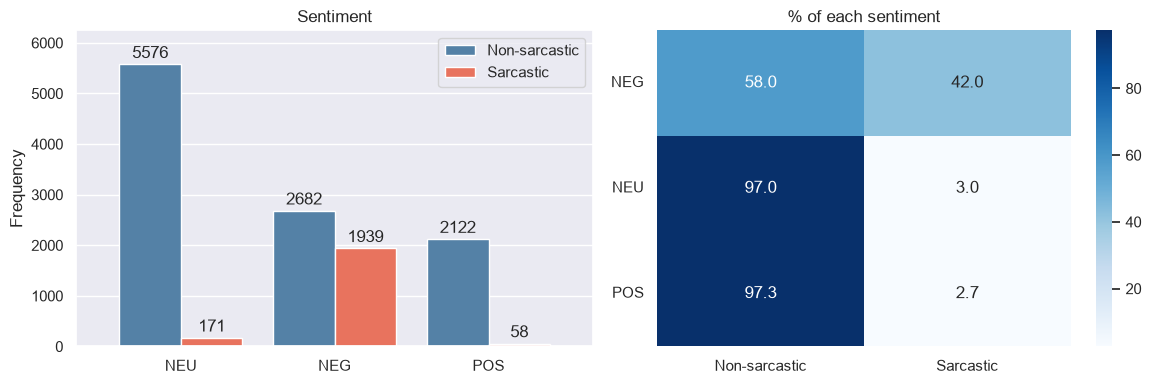

In [4]:
# Sentiment vs sarcasm: counts, and % of each sentiment
ct = pd.crosstab(df["sentiment"], df["label"])[LABELS]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = sns.countplot(data=df, x="sentiment", hue="label", hue_order=LABELS, palette=COLORS, ax=axes[0])
bar_labels(ax)
ax.set(xlabel="", ylabel="Frequency", title="Sentiment")
ax.legend(title="")

sns.heatmap(ct.div(ct.sum(axis=1), axis=0) * 100, annot=True, fmt=".1f", cmap="Blues", ax=axes[1])
axes[1].set(xlabel="", ylabel="", title="% of each sentiment")
axes[1].tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()

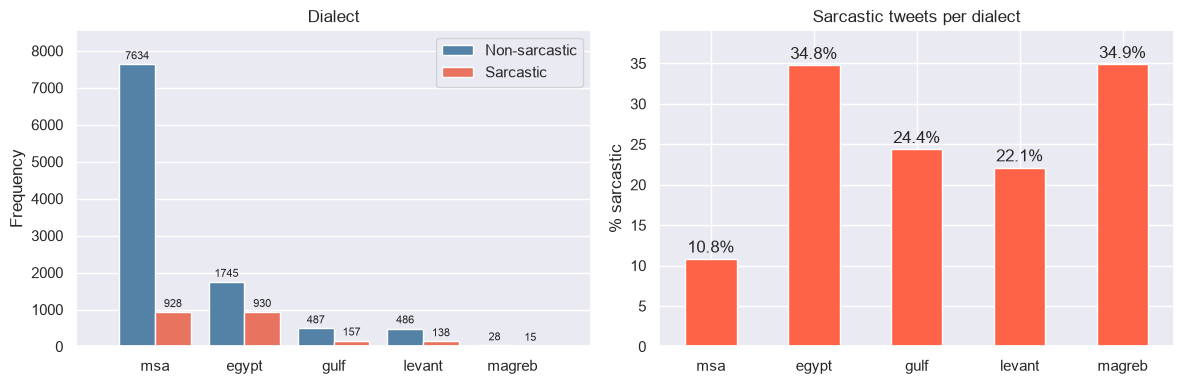

In [5]:
# Dialect vs sarcasm: counts, and % sarcastic per dialect
order = df["dialect"].value_counts().index

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = sns.countplot(data=df, x="dialect", order=order, hue="label", hue_order=LABELS, palette=COLORS, ax=axes[0])
bar_labels(ax, fontsize=8)
ax.set(xlabel="", ylabel="Frequency", title="Dialect")
ax.legend(title="")

pct = df.groupby("dialect")["sarcasm"].mean().mul(100).loc[order]
ax = pct.plot.bar(ax=axes[1], rot=0, color="tomato")
bar_labels(ax, "%.1f%%")
ax.set(xlabel="", ylabel="% sarcastic", title="Sarcastic tweets per dialect")

plt.tight_layout()
plt.show()

In [6]:
# 30 raw tweets from train and 30 from test (repr makes quotes and trailing spaces visible)
raw = pd.concat([
    df[["tweet"]].sample(30, random_state=42).assign(split="train"),
    test[["tweet"]].sample(30, random_state=42).assign(split="test"),
], ignore_index=True)
raw["tweet"] = raw["tweet"].map(repr)

with pd.option_context("display.max_colwidth", None, "display.max_rows", None):
    display(raw)

,tweet,split
0,"'""منعرف مين قتل جبران! رح نقاتله بالحرية. بالحرية وبس...#جبران_تويني https://t.co/KhKtsbqWZY""'",train
1,'(وإنما الأمم الأخلاق ما بقيت فـإن هُمُوُ ذهبــت أخـلاقهم ذهــبوا) #خلق_جميل #خلق_جميل',train
2,"'""اللهم أستودعك أهلي وأحبتياللهم أستودعك بلادي #ليبيا وأهلها وشبابها اللهم أنعم علينا بالأمان والاستقرار وحسن المعيشة والتغيير للأفضل""'",train
3,"'""@i_FHD0 مو اعلان حتى، كده سلفي""'",train
4,"'""مشروع القرار الذي طرحته فرنسا حول إرسال مراقبين دوليين الى حلب لمراقبة عملية الاخلاء والذي صوت عليه بالإجماع اليوم… https://t.co/PrLpM0G2NR""'",train
5,'أنا أبكي !! وأدري أن دموع العين خذلان وملح !! #محمود درويش',train
6,'#تخيل إنك أعمى ؟ أو مكفوف ؟ لا سمح الله أكثر الناس راح يقدرون النعمة إذا فقدوهآ ! #حقيقه',train
7,"'""@TeacherQ86 @azisiri ثلاث وزيرات للدفاع بحلف الناتو ايطاليا وهولندا والدنمارك ومبركل ورئيسه وزراء بريطانيا تنقدين ع معصومه المبارك ولاهند""'",train
8,'جامعة سامي اهم 👨🏻\u200d💻',train
9,"'""لما لم نسمع أن النظام المروكي يجنس فنانين من بلدان عربية كالخليجين والمشارقة مثل مريم فارس رامي عياش و..ممن لهم مستثمرات في المغرب #الجزائر""'",train


In [7]:
# Sample tweets per sentiment x sarcasm
def show_samples(by, n):
    for key, group in df.groupby(by):
        print(f"\n{'#' * 60}\n{' | '.join(map(str, key))}  ({len(group)} tweets)\n{'-' * 60}")
        for i, tweet in enumerate(group["tweet"].sample(min(n, len(group)), random_state=42), 1):
            print(f"{i}. {tweet}\n")

show_samples(["sentiment", "label"], 5)


############################################################
NEG | Non-sarcastic  (2682 tweets)
------------------------------------------------------------
1. أنا ساعات كتير ببقى عايز أبقى متحضر يا جماعة بس مابعرفش 󾌴 هاموت نفسي يعني 󾌴  

2. شوف حجم التهليل والتكبير التهليل والتكبير لقتل رجل لم يصوب لك سلاحاً

3. "حتی بالانمي نشيت لنا هاللعبة 😂💔#جيمرز #بوكيمون_قو #جيمر https://t.co/MDY8IBbnHM"

4. "RT @QablQalel: مندوب اﻷسد بشار الجعفري واضعا يده بحميمية على ظهر مندوب مصر خلال حديثهما قبيل التصويت لروسيا..#مصر_تصوت_لصالح_المشروع_الر…"

5. "الرياضة اليوم ذُعر في برشلونة بعد أنباء إصابة “سواريز” https://t.co/RwMEaO7KGD https://t.co/pImPvLPpOJ"


############################################################
NEG | Sarcastic  (1939 tweets)
------------------------------------------------------------
1. "RT @b7741o8558b: @kingksayemen @YouTube ثأرنا لن نتركه وسنأخذه ضعفيناستعدوا يا مملكة الارهاب الداعشيةفوالله العظيم انكم حفرتم قبوركم بأي…"

2. #إخوان باعو,,,#عسكر خانو!

3. 2008 بعد ان عرفنا

In [8]:
# Sample tweets per dialect x sarcasm
show_samples(["dialect", "label"], 2)


############################################################
egypt | Non-sarcastic  (1745 tweets)
------------------------------------------------------------
1. "I liked a @YouTube video from @med0009 https://t.co/9vZ4UR3yLo نوال الزغبي و وائل كفوري مين حبيبي"

2. خلاصة كلامي: خايف من انفراد فصيل سياسي بالسلطة؟ انضم لحزب ينافسه وابذل جهدك لنجاح الحزب في انتخابات مجلس الشعب القادمة والفرص فعلا متاحة


############################################################
egypt | Sarcastic  (930 tweets)
------------------------------------------------------------
1. "@91hm11 وين الناتو يا معتوه ؟؟التريس تكسب والـ***** تحسب"

2. #علاء_عبد_الفتاح زعلان أنى الميسيحين #بيصقفو #للسيسى وبيفكر #الميسيحين بى #ماسبيرو علاء #وشلتو #الدم هو #تجارتهم_الرابحة لى…


############################################################
gulf | Non-sarcastic  (487 tweets)
------------------------------------------------------------
1. "@mohmad3033 والله مهو كلهم يبو سلطان..الاعلام الغربي يبي يصور لنا ان الشيعة خطر ويبي ي

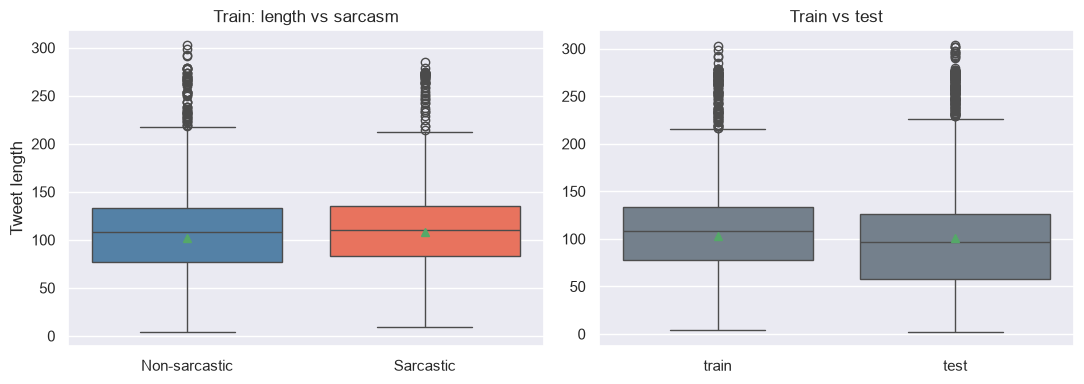

In [9]:
# Tweet length
lengths = pd.concat([df.assign(split="train"), test.assign(split="test")])
lengths["length"] = lengths["tweet"].str.len()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.boxplot(data=lengths[lengths["split"] == "train"], x="label", y="length", order=LABELS,
            hue="label", palette=COLORS, legend=False, showmeans=True, ax=axes[0])
axes[0].set(xlabel="", ylabel="Tweet length", title="Train: length vs sarcasm")

sns.boxplot(data=lengths, x="split", y="length", color="slategray", showmeans=True, ax=axes[1])
axes[1].set(xlabel="", ylabel="", title="Train vs test")

plt.tight_layout()
plt.show()

In [10]:
# Top 10 emojis per class (appearances per 1,000 tweets)
class_sizes = df["label"].value_counts()[LABELS]
tweet_emojis = df["tweet"].map(lambda t: [e["emoji"] for e in emoji.emoji_list(t)])

emoji_counts = pd.DataFrame({
    lab: Counter(e for es in tweet_emojis[df["label"] == lab] for e in es) for lab in LABELS
}).fillna(0)
emoji_rates = emoji_counts.div(class_sizes) * 1000

top10 = emoji_rates.sum(axis=1).nlargest(10).index
plot_data = (emoji_rates.loc[top10]
             .rename_axis("Emoji").reset_index()
             .melt(id_vars="Emoji", var_name="Class", value_name="Appearances per 1,000 tweets"))

fig = px.bar(plot_data, x="Appearances per 1,000 tweets", y="Emoji", color="Class",
             barmode="group", orientation="h", color_discrete_map=COLORS, title="Top 10 emojis by class")
fig.update_yaxes(autorange="reversed")
fig.update_layout(height=500)
fig.show()

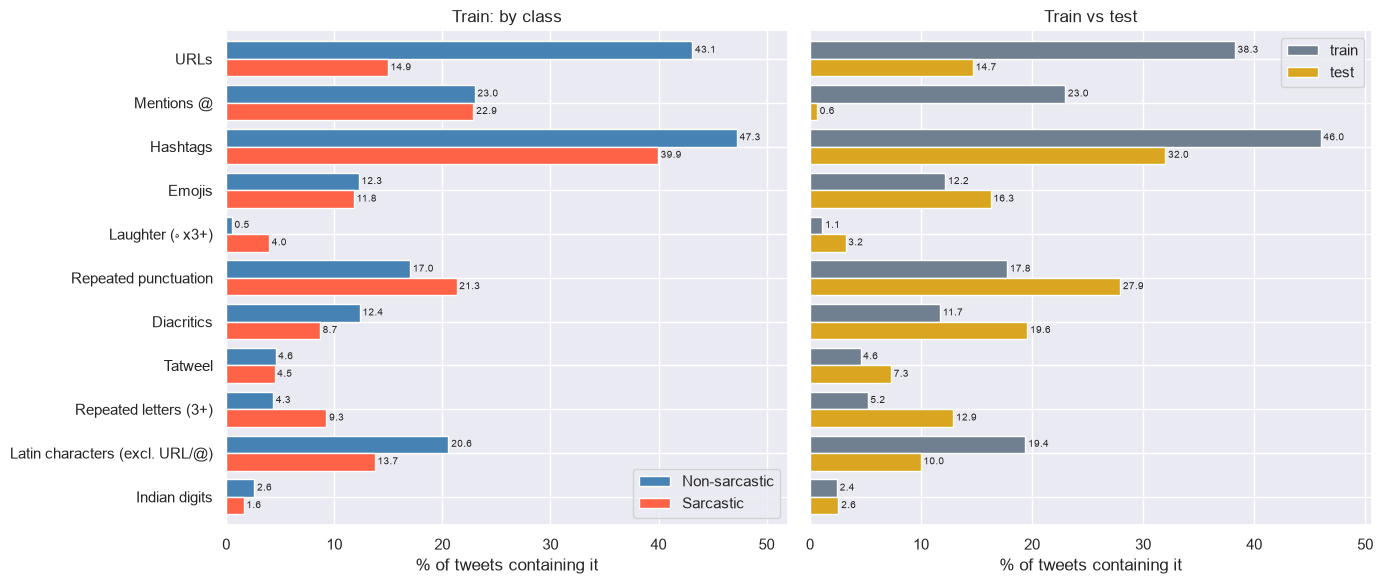

In [19]:
# Feature counts: % of tweets containing each feature, by class (train) and train vs test
URL = URL_PATTERN.pattern

FEATURES = {
    "URLs": lambda s: s.str.count(URL),
    "Mentions @": lambda s: s.str.count(r"(?<!\w)@\w+"),
    "Hashtags": lambda s: s.str.count(r"(?<!\w)#\w+"),
    "Emojis": lambda s: s.map(emoji.emoji_count),
    "Laughter (ه x3+)": lambda s: s.str.count(r"ه{3,}"),
    "Repeated punctuation": lambda s: s.str.count(r"([!?.،؟,;:])\1+"),
    "Diacritics": lambda s: s.str.count(r"[\u064B-\u0652]"),
    "Tatweel": lambda s: s.str.count("\u0640"),
    "Repeated letters (3+)": lambda s: s.str.count(r"([^\W\d_])\1{2,}"),
    "Latin characters (excl. URL/@)": lambda s: (s.str.replace(URL, " ", regex=True)
                                                  .str.replace(r"@\w+", " ", regex=True)
                                                  .str.count(r"[A-Za-z]")),
    "Indian digits": lambda s: s.str.count(r"[\u0660-\u0669]"),
}

present = {name: (fn(df["tweet"]) > 0, fn(test["tweet"]) > 0) for name, fn in FEATURES.items()}

by_class = pd.DataFrame({
    lab: {n: 100 * p[0][df["label"] == lab].mean() for n, p in present.items()} for lab in LABELS
})
by_split = pd.DataFrame({
    "train": {n: 100 * p[0].mean() for n, p in present.items()},
    "test": {n: 100 * p[1].mean() for n, p in present.items()},
})

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

by_class.plot.barh(ax=axes[0], color=[COLORS[l] for l in by_class.columns], width=0.8)
axes[0].set(title="Train: by class", xlabel="% of tweets containing it")

by_split.plot.barh(ax=axes[1], color=["slategray", "goldenrod"], width=0.8)
axes[1].set(title="Train vs test", xlabel="% of tweets containing it")

for ax in axes:
    bar_labels(ax, "%.1f", fontsize=7)
    ax.legend(title="")
axes[0].invert_yaxis()

plt.tight_layout()
plt.show()

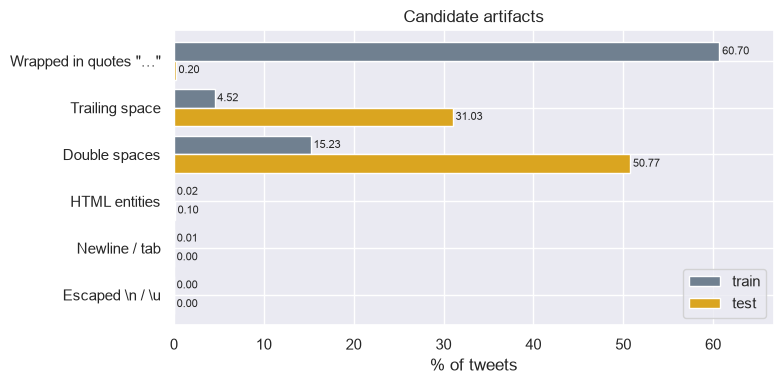

In [12]:
# Format artifacts: candidates, train vs test
def wrapped_in_quotes(s):
    s = s.str.strip()
    return s.str.startswith('"') & s.str.endswith('"') & (s.str.len() > 1)

CANDIDATES = {
    'Wrapped in quotes "…"': wrapped_in_quotes,
    "Trailing space": lambda s: s.str.contains(r"\s$"),
    "Double spaces": lambda s: s.str.contains(r"\s{2,}"),
    "HTML entities": lambda s: s.str.contains(r"&(?:amp|lt|gt|quot|apos|nbsp|#\d+);"),
    "Newline / tab": lambda s: s.str.contains(r"[\n\r\t]"),
    "Escaped \\n / \\u": lambda s: s.str.contains(r"\\[nrtu]"),
}

cand = pd.DataFrame({
    "train": {n: 100 * fn(df["tweet"]).mean() for n, fn in CANDIDATES.items()},
    "test": {n: 100 * fn(test["tweet"]).mean() for n, fn in CANDIDATES.items()},
})

ax = cand.plot.barh(figsize=(8, 4), color=["slategray", "goldenrod"], width=0.8)
bar_labels(ax, "%.2f", fontsize=8)
ax.invert_yaxis()
ax.set(xlabel="% of tweets", title="Candidate artifacts")
plt.tight_layout()
plt.show()

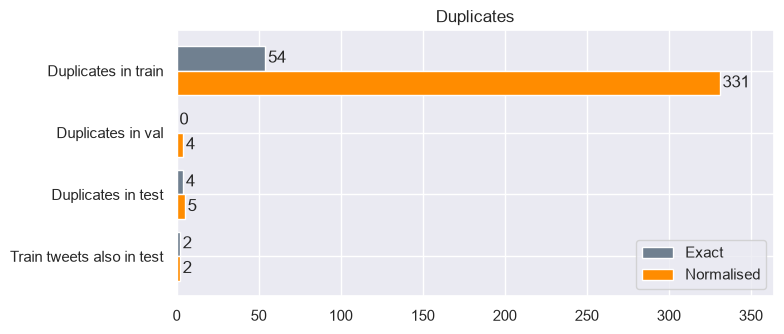

In [20]:
# Duplicates: exact vs normalised
train_k, val_k, test_k = (add_key(f) for f in (train, val, test))
train_clean, report, conflicts = clean_train(train_k, val_k, test_k)

dups = pd.DataFrame({
    label: {
        "Duplicates in train": report[f"{key}/dup_train"],
        "Duplicates in val": report[f"{key}/dup_val"],
        "Duplicates in test": report[f"{key}/dup_test"],
        "Train tweets also in test": report[f"{key}/train_in_test"],
    }
    for label, key in [("Exact", "key_exact"), ("Normalised", "key")]
})

ax = dups.plot.barh(figsize=(8, 3.5), color=["slategray", "darkorange"], width=0.8)
bar_labels(ax)
ax.invert_yaxis()
ax.set(title="Duplicates")
plt.tight_layout()
plt.show()

In [ ]:

print(f"Contradictory groups: {report['conflict_groups']} ({report['conflict_rows']} tweets)")

with pd.option_context("display.max_colwidth", 90):
    display(conflicts[["tweet", "sarcasm", "split"]].head(6))

Contradictory groups: 59 (120 tweets)


,tweet,sarcasm,split
3900,@238Reaam مش طالبة هاري بوتر قسما بالله 😂,0,train
5728,"""@238Reaam مش طالبة هاري بوتر قسما بالله 😂""",1,train
10385,"""@Bankerchy ههههههههههههههه اي ذكرني بعيد ميلادك اجيب لك نفس بومة هاري بوتر تستاهل""",0,train
3743,@Bankerchy ههههههههههههههه اي ذكرني بعيد ميلادك اجيب لك نفس بومة هاري بوتر تستاهل,1,val
8899,"""@Godphobia1 @3lya12 @mm__ss55 @usten_moon انصحك نصيحة صار لك في غرب وقت اذا لماذا لا ...",1,train
11785,@Godphobia1 @3lya12 @mm__ss55 @usten_moon انصحك نصيحة صار لك في غرب وقت اذا لماذا لا ت...,0,train


Tweets de train présents dans test (retirés) : 2


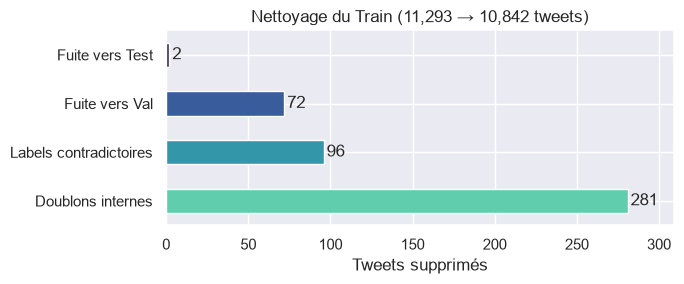

In [23]:
# Train cleaning: tweets removed per reason
print(f"Tweets de train présents dans test (retirés) : {report['removed_in_test']}")

removed = pd.Series({
    "Fuite vers Test": report["removed_in_test"],
    "Fuite vers Val": report["removed_in_val"],
    "Labels contradictoires": report["removed_conflicting"],
    "Doublons internes": report["removed_duplicates"],
})

ax = removed.plot.barh(figsize=(7, 3), color=sns.color_palette("mako", 4))
bar_labels(ax)
ax.invert_yaxis()
ax.set(xlabel="Tweets supprimés", title=f"Nettoyage du Train ({report['start']:,} → {report['end']:,} tweets)")
plt.tight_layout()
plt.show()